# Detecting Swimming Pools using Automated Deep Learning
* 🔬 Data Science
* 🥠 Deep Learning and Object Detection

## Table of Contents
* [Introduction and objective](#Introduction-and-objective)
* [Part 1 - Export training data](#Part-1---Export-training-data)
* [Part 2 - model training](#Part-2---model-training)
    * [Necessary imports](#Necessary-imports)
    * [Prepare data that will be used for training](#Prepare-data-that-will-be-used-for-training)
    * [Visualize training data](#Visualize-training-data)
    * [Load model architecture](#Load-model-architecture)
    * [Train the model](#Train-the-model)
    * [Detect and visualize swimming pools in validation set](#Detect-and-visualize-swimming-pools-in-validation-set)
    * [Save the model](#Save-the-model) 
* [Part 3 - Model inference](#Part-3---Model-inference)
    * [Visualize detected pools on map](#Visualize-detected-pools-on-map)
* [Conclusion](#Conclusion)
* [References](#References)

## Introduction and objective

Deep Learning has achieved great success with state of the art results, but taking it to the field and solving real-world problems is still a challenge. Integration of the latest research in AI with ArcGIS opens up a world of opportunities. This notebook demonstrates an end-to-end deep learning workflow in using `ArcGIS API for Python`. The workflow consists of three major steps: (1) extract training data, (2) train a deep learning object detection model, (3) deploy the model for inference and create maps. To better illustrate this process, we choose detecting swmming pools in Redlands, CA using remote sensing imagery.

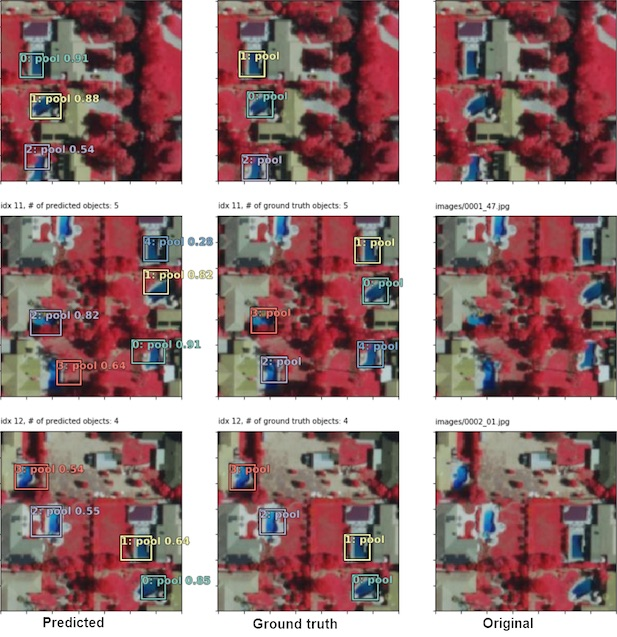

## Part 1 - Export training data

To export training data, we need a labeled feature class that contains the bounding box for each object, and a raster layer that contains all the pixels and band information. In this swimming pool detection case, we have created feature class by hand labelling the bounding box of each swimming pool in Redlands using ArcGIS Pro and USA NAIP Imagery: Color Infrared as raster data.

In [1]:
from arcgis.gis import GIS

# Connect to gis
gis = GIS('home')

<Item title:"SwimmingPoolLabels" type:Feature Layer Collection owner:api_data_owner>
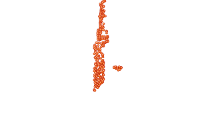

In [2]:
pool_bb = gis.content.get('0da0026a3a6d47dc8da0bcff6cf5bfb2')
pool_bb

<Item title:"NAIP_Imagery" type:Tiled Imagery Layer owner:api_data_owner>
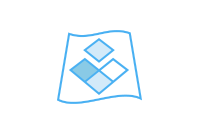

In [3]:
naip_item = gis.content.get('41f2bbe1f73f4388a2e1694df437f265')
naip_item

With the feature class and raster layer, we are now ready to export training data using the 'Export Training Data For Deep Learning' tool in arcgis Pro. In addtion to feature class, raster layer, and output folder, we also need to speficy a few other parameters such as tile size (size of the image chips), stride size (distance to move in the X when creating the next image chip), chip format (TIFF, PNG, or JPEG), metadata format (how we are going to store those bounding boxes). 

Depending on the size of your data, tile and stride size, and computing resources, this opertation can take 15mins~2hrs in our experiment. Also, do not re-run it if you already run it once unless you would like to update the setting.

<img src="data:image/PNG; base64, ...">

## Part 2 - model training

If you've already done part 1, you should already have both the training chips and swimming pool labels. Please change the path to your own export training data folder that contains "images" and "labels" folder.

### Necessary imports

In [4]:
import os
import zipfile
from pathlib import Path

from arcgis.learn import prepare_data, AutoDL, ImageryModel

<Item title:"detecting_swimming_pools_using_satellite_image_and_deep_learning" type:Image Collection owner:api_data_owner>
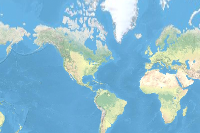

In [5]:
training_data = gis.content.get('73a29df69b344ce8b94fdb4c9df7103d')
training_data

In [6]:
filepath = training_data.download(file_name=training_data.name)

In [7]:
# Unzip training data
with zipfile.ZipFile(filepath, 'r') as zip_ref:
    zip_ref.extractall(Path(filepath).parent)

In [8]:
data_path = Path(os.path.join(os.path.splitext(filepath)[0]))

### Prepare data that will be used for training

In [9]:
data = prepare_data(data_path, 
                    batch_size=4, 
                    chip_size=448,
                    class_mapping={'0': 'pool'})
data.classes

['background', 'pool']

### Visualize training data
To get a sense of what the training data looks like, `arcgis.learn.show_batch()` method randomly picks a few training chips and visualize them.

CPU times: total: 20.1 s
Wall time: 1.24 s


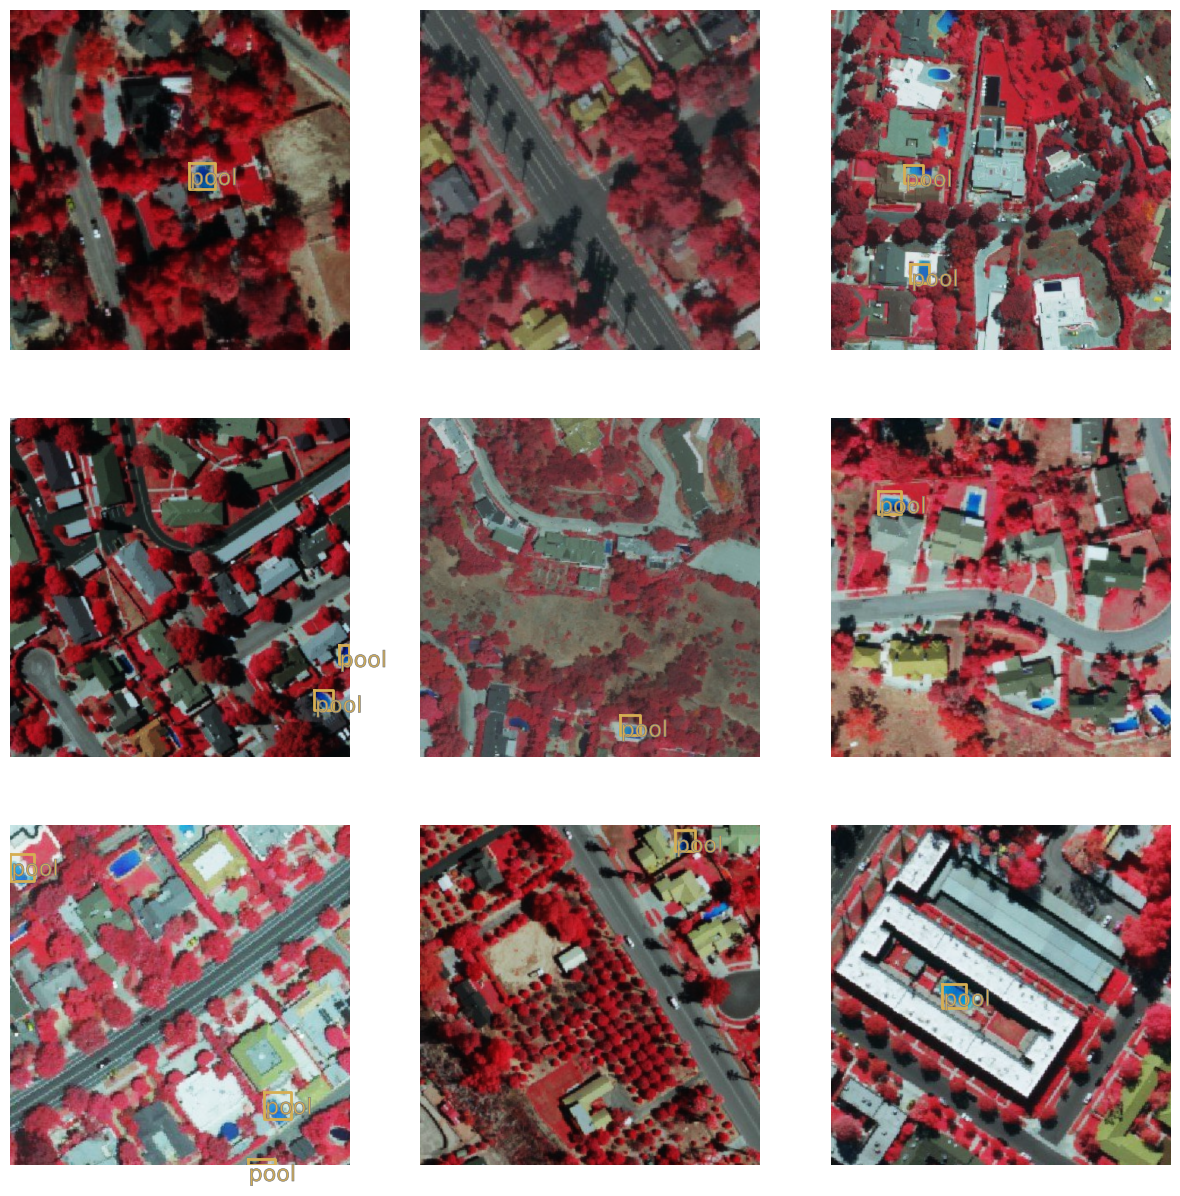

In [10]:
%%time
data.show_batch()

### Load model architecture


In [11]:
model = AutoDL(data, total_time_limit=0.30)

Given time to process the dataset is: 0.3 hours
Number of images that can be processed in the given time: 5.0
Time required to process the entire dataset of 1845 images is 99.57 hours


In [12]:
%%time
model.fit()

09-09-2024 20:04:31: Selected networks: SingleShotDetector RetinaNet FasterRCNN YOLOv3 DETReg ATSS CARAFE CascadeRCNN CascadeRPN DCN Detectors DoubleHeads DynamicRCNN EmpiricalAttention FCOS FoveaBox FSAF GHM LibraRCNN PaFPN PISA RegNet RepPoints Res2Net SABL VFNet
09-09-2024 20:04:31: Current network - SingleShotDetector. 
09-09-2024 20:04:31: Total time alloted to train the SingleShotDetector model is 0:00:16
09-09-2024 20:04:31: Maximum number of epochs will be 20 to train SingleShotDetector
09-09-2024 20:04:31: Initializing the SingleShotDetector network.
09-09-2024 20:05:19: SingleShotDetector initialized with resnet34 backbone
09-09-2024 20:05:19: finding desired batch size for the data object.
09-09-2024 20:05:19: Optimized batch size for SingleShotDetector with the selected backbone is 64
09-09-2024 20:05:47: Best learning rate for SingleShotDetector with the selected data is 0.00363078054770101
09-09-2024 20:05:47: Fitting SingleShotDetector
09-09-2024 20:06:28: Training compl

09-09-2024 20:50:27: Finished training RetinaNet.
09-09-2024 20:50:27: Exiting.
09-09-2024 20:50:27: Saving the model
Computing model metrics...


09-09-2024 20:50:48: model saved at ~\AppData\Local\Temp\detecting_swimming_pools_using_satellite_image_and_deep_learning\models\AutoDL_RetinaNet_resnet50_2024-09-09_20-50-15
09-09-2024 20:50:49: Current network - FasterRCNN. 
09-09-2024 20:50:49: Total time alloted to train the FasterRCNN model is 0:00:30
09-09-2024 20:50:49: Insufficient time to train the FasterRCNN for 20 epochs. 0 epochs can only be trained in the remaining time.
09-09-2024 20:50:49: The time left to train the FasterRCNN is not sufficent.
09-09-2024 20:50:49: Remaining networks will be skipped due to limited time, Stopping the training process.
09-09-2024 20:50:49: Collating and evaluating model performances.
09-09-2024 20:50:49: Exiting.
CPU times: total: 2h 9min 57s
Wall time: 46min 17s


### Get the best model path

In [13]:
path = Path(os.getenv('APPDATA')).parents[0]
path = Path(path, 'Local\Temp\detecting_swimming_pools_using_satellite_image_and_deep_learning\models')

In [14]:
best_backbone = model._best_backbone
best_model = model.best_model
best_model, best_backbone

('SingleShotDetector', 'resnet34')

In [15]:
model.score() # Check the scores and other details of the trained models

,Model,train_loss,valid_loss,average_precision_score,lr,training time,backbone
0,SingleShotDetector,450.839417,155.492569,0.010427,0.003631,0:01:56,resnet34
1,RetinaNet,3.292400,3.414389,0.000439,0.000091,0:43:05,resnet50


In [16]:
files = [f for f in path.iterdir() if f.is_dir()]
folder_list = []

for file in files:
    if best_model in file.name and best_backbone in file.name:
        folder = file.name
        folder_list.append(folder)
        
best_model_folder = sorted(folder_list)[-1]
emd_file = best_model_folder + '.emd'

path = Path(path, best_model_folder, emd_file)
path = os.path.abspath(path) #path of the best model

In [17]:
score = model.average_precision_score()
score.sort_values(by='pool', ascending=False)

,Model,pool
0,SingleShotDetector,0.010427
0,RetinaNet,0.000439


### Finetuning best model

In [18]:
from arcgis.learn import ImageryModel

In [19]:
finetune_model = ImageryModel()

In [20]:
finetune_model.load(path, data)

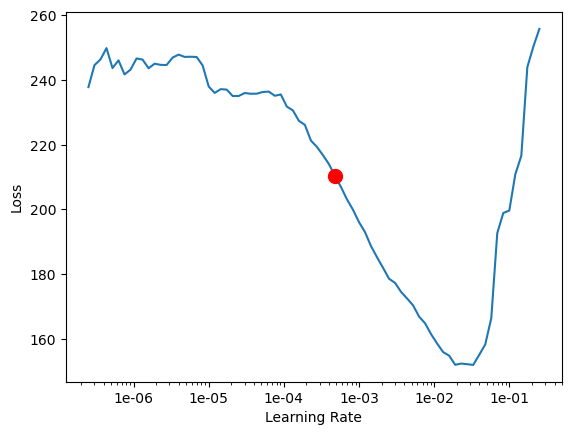

In [21]:
lr = finetune_model.lr_find()

In [22]:
finetune_model.fit(epochs=10, lr=lr)

epoch,train_loss,valid_loss,average_precision,time
0,47.962368,45.468967,0.185395,02:20
1,37.229790,37.099052,0.499507,02:21
2,32.476410,36.612148,0.440375,02:20
3,29.966869,33.942570,0.511389,02:21
4,30.256081,34.916912,0.461470,02:20
5,28.695295,33.780155,0.501860,02:20
6,27.232103,36.281372,0.425415,02:19
7,24.844667,36.177143,0.442514,02:20
8,25.169331,32.932259,0.481551,02:20
9,25.038212,32.194958,0.503439,02:20


In [23]:
finetune_model.average_precision_score()

{'pool': 0.5034394905969962}

In [24]:
finetune_model.fit(epochs=10)

epoch,train_loss,valid_loss,average_precision,time
0,24.063225,32.582569,0.495154,02:22
1,23.060495,35.708080,0.424427,02:22
2,22.952930,32.752361,0.487197,02:25
3,23.241489,33.141312,0.477005,02:22
4,26.947018,34.039207,0.465994,02:25
5,26.588541,34.467522,0.448040,02:23
6,24.711823,33.374062,0.466779,02:23
7,23.389183,33.137882,0.475220,02:22
8,25.681923,32.232948,0.491468,02:23
9,25.366545,32.406380,0.489742,02:21


In [25]:
finetune_model.average_precision_score()

{'pool': 0.4914678402778204}

### Detect and visualize swimming pools in validation set
Now we have the model, let's look at how the model performs. Here we plot out 5 rows of images and a threshold of 0.2. Threshold is a measure of probablity that a swimming pool exists. Higher value meas more confidence.

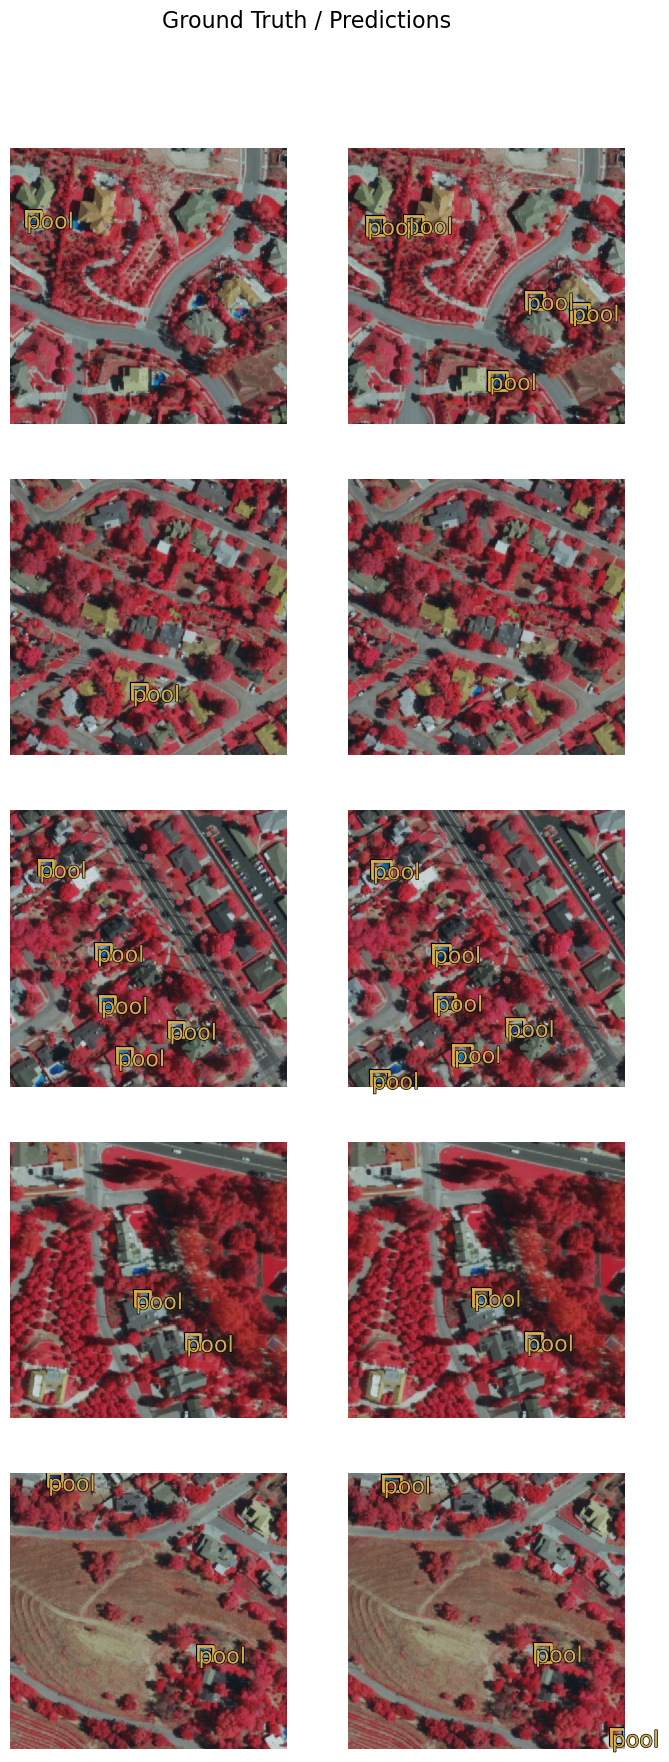

In [26]:
finetune_model.show_results(thresh=0.2)

As we can see, with only 20 epochs, we are already seeing reasonable results. Further improvment can be acheived through more sophisticated hyperparameter tuning. Let's save the model for further training or inference later. The model should be saved into a models folder in your folder. By default, it will be saved into your `data_path` that you specified in the very beginning of this notebook.

In [27]:
finetune_model.save('PoolDetection_USA_20')

Computing model metrics...


WindowsPath('~/AppData/Local/Temp/detecting_swimming_pools_using_satellite_image_and_deep_learning/models/PoolDetection_USA_20')

## Part 3 -  Model inference
To test our model, let's get a raster image with some swimming pools.

<img src="data:image/PNG; base64, ...">

## Visualize detected pools on map

<Item title:"detected_pools" type:Feature Layer Collection owner:api_data_owner>
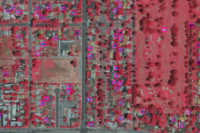

In [28]:
predicted_result = gis.content.get('793d2060d14746d19ee4c45d3eda7724')
predicted_result

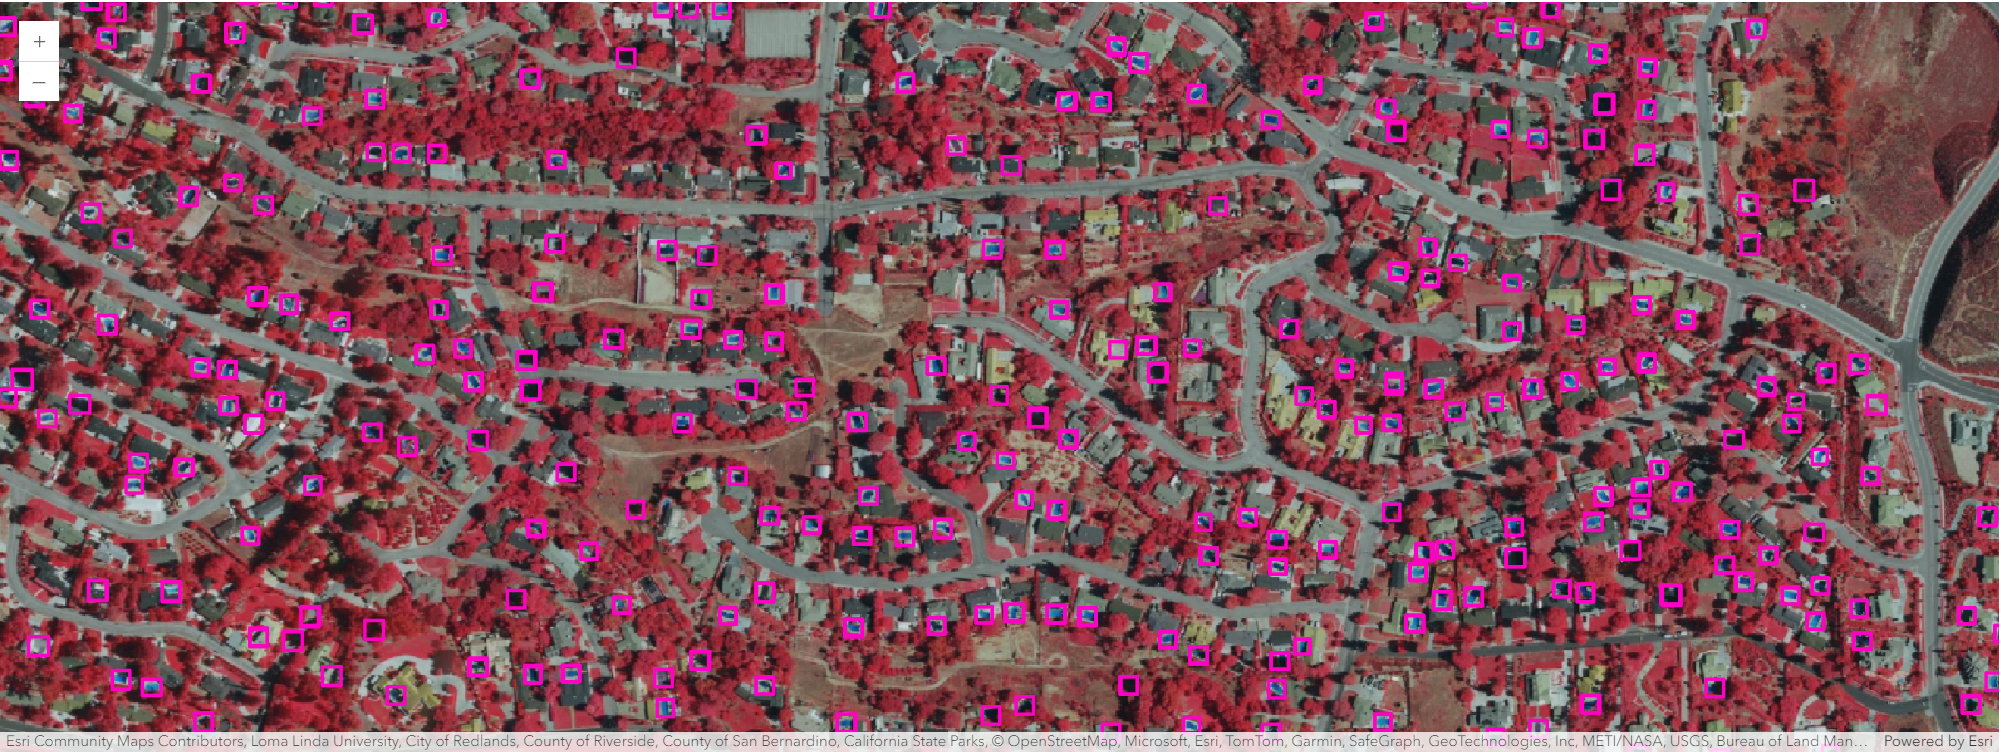

In [29]:
result_map = gis.map('Redlands, CA')
result_map.content.add(naip_item.layers[0])
result_map.content.add(predicted_result.layers[0])
result_map.extent = {'spatialReference': {'latestWkid': 3857, 'wkid': 102100},
                      'xmin': -13041805.641506677,'ymin': 4032306.1515633,
                      'xmax': -13039489.838415546,'ymax': 4033022.7487034127}
result_map

## Conclusion
In thise notebook, we have covered a lot of ground. In part 1, we discussed how to export training data for deep learning using ArcGIS Pro, we demonstrated how to prepare the input data, train a object detection model, visualize the results, as well as apply the model to an unseen image using the Detect Objects Using Deep Learning tool in ArcGIS Pro. 

## References
[1]
Wei Liu, Dragomir Anguelov, Dumitru Erhan, Christian Szegedy, Scott Reed, Cheng-Yang Fu: “SSD: Single Shot MultiBox Detector”, 2015; <a href='http://arxiv.org/abs/1512.02325'>arXiv:1512.02325</a>.